In [1]:
# packages
from pathlib import Path
from char_tokenizer import build_char_vocab, char_encode
from bpe_tokenizer import bpe_load_tokenizer
from transformer import Transformer
from data_loader import load_id,chunking,loading
import torch
import json
import matplotlib.pyplot as plt

# Initial Analysis

In [2]:
file_names = ["en.txt","tr.txt","zh.txt"]
file_path = Path("Data/train/")

In [3]:
def count_characters(filename):
    char_set = set()
    with open(filename,"r",encoding="utf-8") as file:
        for line in file:
           #print(line)
            char_set.update(line)
    return char_set

In [4]:
eng_char = count_characters(file_path/file_names[0])
print(f"Unique characters in English : {len(eng_char)}")
zh_char = count_characters((file_path/file_names[1]))
print(f"Unique characters in Chinese : {len(zh_char)}")
tr_char = count_characters(file_path/file_names[2])
print(f"Unique characters in Turkish : {len(tr_char)}")
print(f"Sum of characters when manual addition : {len(eng_char)+len(zh_char)+len(tr_char)}")
combined_set = eng_char|zh_char|tr_char
print(f"Sum of characters when union : {len(combined_set)} ")

Unique characters in English : 679
Unique characters in Chinese : 509
Unique characters in Turkish : 9216
Sum of characters when manual addition : 10404
Sum of characters when union : 9443 


# Part 1: the tokenizers

In [5]:
ch_id_dict,id_ch_dict = build_char_vocab(file_names,file_path)
small_bpe_tokenizer = bpe_load_tokenizer("bpe_data/small_tokenizer.json")
large_bpe_tokenizer = bpe_load_tokenizer("bpe_data/large_tokenizer.json")
print(len(ch_id_dict))
print(small_bpe_tokenizer.get_vocab_size())
print(large_bpe_tokenizer.get_vocab_size())

9444
2000
10000


In [6]:
##  character level tokenizer for all languages

def count_total_tokens(filepath):
    total_tokens = 0
    counter = 0
    with open(filepath, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()
            encoded =  char_encode(line,ch_id_dict)
            total_tokens = total_tokens + len(encoded)
            counter = counter +1
    return total_tokens,counter
    
total,sentences = count_total_tokens("Data/valid/en.txt")
avg_token_per_sentence = total/sentences
print("Character level tokenizer for Engish Valid set")
print(f"Total number of tokens : {total}")
print(f"Average number of tokens per sentence : {avg_token_per_sentence}")
print("=====================================================")
total,sentences = count_total_tokens("Data/valid/tr.txt")
avg_token_per_sentence = total/sentences
print("Character level tokenizer for Turkish Valid set")
print(f"Total number of tokens : {total}")
print(f"Average number of tokens per sentence : {avg_token_per_sentence}")
print("=====================================================")
total,sentences = count_total_tokens("Data/valid/zh.txt")
avg_token_per_sentence = total/sentences
print("Character level tokenizer for Chinese Valid set")
print(f"Total number of tokens : {total}")
print(f"Average number of tokens per sentence : {avg_token_per_sentence}")
print("=====================================================")

Character level tokenizer for Engish Valid set
Total number of tokens : 368269
Average number of tokens per sentence : 81.11651982378855
Character level tokenizer for Turkish Valid set
Total number of tokens : 368383
Average number of tokens per sentence : 98.62998661311914
Character level tokenizer for Chinese Valid set
Total number of tokens : 368266
Average number of tokens per sentence : 38.545740004186726


In [7]:
## all text file and small bpe
def count_total_tokens_bpe(filepath,tokenizer):
    total_tokens = 0
    counter = 0
    with open(filepath, "r", encoding="utf-8") as file:
        for line in file:
            line = line.strip()
            encoded =  tokenizer.encode(line)
            total_tokens = total_tokens + len(encoded)
            counter = counter + 1
    return total_tokens,counter
    
total,sentences = count_total_tokens_bpe("Data/valid/en.txt",small_bpe_tokenizer)
avg_token_per_sentence = total / sentences
print("Small BPE tokenizer for English Valid set")
print(f"Total number of tokens : {total}")
print(f"Average number of tokens per sentence : {avg_token_per_sentence}")
print("=====================================================")
total, sentences = count_total_tokens_bpe("Data/valid/tr.txt", small_bpe_tokenizer)
avg_token_per_sentence = total / sentences
print("Small BPE tokenizer for Turkish Valid set")
print(f"Total number of tokens : {total}")
print(f"Average number of tokens per sentence : {avg_token_per_sentence}")
print("=====================================================")
total, sentences = count_total_tokens_bpe("Data/valid/zh.txt", small_bpe_tokenizer)
avg_token_per_sentence = total / sentences
print("Small BPE tokenizer for Chinese Valid set")
print(f"Total number of tokens : {total}")
print(f"Average number of tokens per sentence : {avg_token_per_sentence}")
print("=====================================================")

total, sentences = count_total_tokens_bpe("Data/valid/en.txt", large_bpe_tokenizer)
avg_token_per_sentence = total / sentences
print("Large BPE tokenizer for English Valid set")
print(f"Total number of tokens : {total}")
print(f"Average number of tokens per sentence : {avg_token_per_sentence}")
print("=====================================================")

total, sentences = count_total_tokens_bpe("Data/valid/tr.txt", large_bpe_tokenizer)
avg_token_per_sentence = total / sentences
print("Large BPE tokenizer for Turkish Valid set")
print(f"Total number of tokens : {total}")
print(f"Average number of tokens per sentence : {avg_token_per_sentence}")
print("=====================================================")

total, sentences = count_total_tokens_bpe("Data/valid/zh.txt", large_bpe_tokenizer)
avg_token_per_sentence = total / sentences
print("Large BPE tokenizer for Chinese Valid set")
print(f"Total number of tokens : {total}")
print(f"Average number of tokens per sentence : {avg_token_per_sentence}")
print("=====================================================")

Small BPE tokenizer for English Valid set
Total number of tokens : 163698
Average number of tokens per sentence : 36.0568281938326
Small BPE tokenizer for Turkish Valid set
Total number of tokens : 168407
Average number of tokens per sentence : 45.08888888888889
Small BPE tokenizer for Chinese Valid set
Total number of tokens : 417488
Average number of tokens per sentence : 43.69771823320075
Large BPE tokenizer for English Valid set
Total number of tokens : 114312
Average number of tokens per sentence : 25.17885462555066
Large BPE tokenizer for Turkish Valid set
Total number of tokens : 113376
Average number of tokens per sentence : 30.355020080321285
Large BPE tokenizer for Chinese Valid set
Total number of tokens : 299555
Average number of tokens per sentence : 31.35388319028679


In [8]:
chars_en = 368269
chars_tr = 368383
chars_zh = 368266
# Character tokenizer
print(chars_en/368269)   
print(chars_tr/368383)   
print(chars_zh/368266)  
# Small BPE
print(chars_en/163698)  
print(chars_tr/168407)   
print(chars_zh/417488)   
# Large BPE
print(chars_en/114312)  
print(chars_tr/113376)  
print(chars_zh/299555)   

1.0
1.0
1.0
2.249685396278513
2.187456578408261
0.8820996052581151
3.2216127790608162
3.2492150014112333
1.2293769090818047


total number of tokens needed to encode the validation set, per tokenizer per language

| Tokenizer    | English | Turkish | Chinese |
|--------------|--------:|--------:|--------:|
| Character    | 368269 | 368383 | 368266 |
| Small BPE    | 163698 | 168407 | 417488 |
| Large BPE    | 114312 | 113376 | 299555 |



Average number of tokens per sentence, per tokenizer and language.

| Tokenizer    | English | Turkish | Chinese |
|--------------|--------:|--------:|--------:|
| Character    |   81.12 |   98.63 |   38.55 |
| Small BPE    |   36.06 |   45.09 |   43.70 |
| Large BPE    |   25.18 |   30.36 |   31.35 |



average number of Unicode characters per token.

| Tokenizer    | English | Turkish | Chinese |
|--------------|--------:|--------:|--------:|
| Character    |    1.00 |    1.00 |    1.00 |
| Small BPE    |    2.25 |    2.19 |    0.88 |
| Large BPE    |    3.22 |    3.25 |    1.23 |



In [9]:
# Example sentence
sentence = "Dalaman nüfusu 2019 yılına göre 42.024 kişidir."
print(f"Sentence : {sentence}")
print("Character tokenizer")
encoded =  char_encode(sentence,ch_id_dict)
print([id_ch_dict[i] for i in encoded])
print("=====================================================")
print("Small BPE")
small_output = small_bpe_tokenizer.encode(sentence)
print(small_output.tokens)
print("=====================================================")
print("Large BPE")
large_output = large_bpe_tokenizer.encode(sentence)
print(large_output.tokens)



Sentence : Dalaman nüfusu 2019 yılına göre 42.024 kişidir.
Character tokenizer
['D', 'a', 'l', 'a', 'm', 'a', 'n', ' ', 'n', 'ü', 'f', 'u', 's', 'u', ' ', '2', '0', '1', '9', ' ', 'y', 'ı', 'l', 'ı', 'n', 'a', ' ', 'g', 'ö', 'r', 'e', ' ', '4', '2', '.', '0', '2', '4', ' ', 'k', 'i', 'ş', 'i', 'd', 'i', 'r', '.']
Small BPE
['ĠD', 'al', 'am', 'an', 'Ġn', 'Ã¼', 'f', 'usu', 'Ġ20', '19', 'ĠyÄ±l', 'Ä±na', 'ĠgÃ¶re', 'Ġ4', '2', '.', '0', '2', '4', 'Ġk', 'iÅŁ', 'idir', '.']
Large BPE
['ĠD', 'alam', 'an', 'ĠnÃ¼fusu', 'Ġ2019', 'ĠyÄ±lÄ±na', 'ĠgÃ¶re', 'Ġ4', '2', '.', '0', '24', 'ĠkiÅŁ', 'idir', '.']


In [10]:
sentence = "在本站往德山方向約200公尺處，"
print(f"Sentence : {sentence}")
print("Character tokenizer")
encoded =  char_encode(sentence,ch_id_dict)
print([id_ch_dict[i] for i in encoded])
print("=====================================================")
print("Small BPE")
small_output = small_bpe_tokenizer.encode(sentence)
print(small_output.tokens)
print("=====================================================")
print("Large BPE")
large_output = large_bpe_tokenizer.encode(sentence)
print(large_output.tokens)


Sentence : 在本站往德山方向約200公尺處，
Character tokenizer
['在', '本', '站', '往', '德', '山', '方', '向', '約', '2', '0', '0', '公', '尺', '處', '，']
Small BPE
['Ġåľ¨', 'æľ¬', 'ç«Ļ', 'å¾Ģ', 'å¾·', 'å±±', 'æĸ¹', 'åĲĳ', 'ç´Ħ', '200', 'åħ¬', 'å°', 'º', 'èĻķ', 'ï¼Į']
Large BPE
['Ġåľ¨', 'æľ¬', 'ç«Ļ', 'å¾Ģ', 'å¾·', 'å±±', 'æĸ¹åĲĳ', 'ç´Ħ', '200', 'åħ¬å°º', 'èĻķ', 'ï¼Į']


In [11]:
sentence = "Sunday edition until his death in 2017."
print(f"Sentence : {sentence}")
print("Character tokenizer")
encoded =  char_encode(sentence,ch_id_dict)
print([id_ch_dict[i] for i in encoded])
print("=====================================================")
print("Small BPE")
small_output = small_bpe_tokenizer.encode(sentence)
print(small_output.tokens)
print("=====================================================")
print("Large BPE")
large_output = large_bpe_tokenizer.encode(sentence)
print(large_output.tokens)


Sentence : Sunday edition until his death in 2017.
Character tokenizer
['S', 'u', 'n', 'd', 'a', 'y', ' ', 'e', 'd', 'i', 't', 'i', 'o', 'n', ' ', 'u', 'n', 't', 'i', 'l', ' ', 'h', 'i', 's', ' ', 'd', 'e', 'a', 't', 'h', ' ', 'i', 'n', ' ', '2', '0', '1', '7', '.']
Small BPE
['ĠS', 'und', 'ay', 'Ġed', 'it', 'ion', 'Ġun', 't', 'il', 'Ġhis', 'Ġde', 'ath', 'Ġin', 'Ġ20', '17', '.']
Large BPE
['ĠS', 'und', 'ay', 'Ġed', 'ition', 'Ġuntil', 'Ġhis', 'Ġdeath', 'Ġin', 'Ġ2017', '.']


# Part 2: the language models 

In [12]:
char_model = Transformer(vocab_size= len(ch_id_dict),hidden_dim=256,seq_len = 128,num_heads = 4,forward_dim=1024,num_layers=2,dropout=0.1)
small_bpe_model = Transformer(vocab_size= 2000,hidden_dim=256,seq_len = 128,num_heads = 4,forward_dim=1024,num_layers=2,dropout=0.1)
large_bpe_model = Transformer(vocab_size= 10000,hidden_dim=256,seq_len = 128,num_heads = 4,forward_dim=1024,num_layers=2,dropout=0.1)

In [13]:
print(char_model)

Transformer(
  (embedding): Embedding(9444, 256)
  (pos_embedding): Embedding(128, 256)
  (layers): ModuleList(
    (0-1): 2 x TransformerLayer(
      (attention): Attention(
        (attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
      )
      (feedforward): FeedForward(
        (linear1): Linear(in_features=256, out_features=1024, bias=True)
        (relu): ReLU()
        (linear2): Linear(in_features=1024, out_features=256, bias=True)
      )
      (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (outputnorm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (outputlayer): Linear(in_features=256, out_features=9444, bias=True)
  (emb_dropout): Dropout(p=0.1, inplace=False)
)


In [14]:
print(small_bpe_model)

Transformer(
  (embedding): Embedding(2000, 256)
  (pos_embedding): Embedding(128, 256)
  (layers): ModuleList(
    (0-1): 2 x TransformerLayer(
      (attention): Attention(
        (attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
      )
      (feedforward): FeedForward(
        (linear1): Linear(in_features=256, out_features=1024, bias=True)
        (relu): ReLU()
        (linear2): Linear(in_features=1024, out_features=256, bias=True)
      )
      (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (outputnorm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (outputlayer): Linear(in_features=256, out_features=2000, bias=True)
  (emb_dropout): Dropout(p=0.1, inplace=False)
)


In [15]:
print(large_bpe_model)

Transformer(
  (embedding): Embedding(10000, 256)
  (pos_embedding): Embedding(128, 256)
  (layers): ModuleList(
    (0-1): 2 x TransformerLayer(
      (attention): Attention(
        (attention): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=256, out_features=256, bias=True)
        )
      )
      (feedforward): FeedForward(
        (linear1): Linear(in_features=256, out_features=1024, bias=True)
        (relu): ReLU()
        (linear2): Linear(in_features=1024, out_features=256, bias=True)
      )
      (norm1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (outputnorm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
  (outputlayer): Linear(in_features=256, out_features=10000, bias=True)
  (emb_dropout): Dropout(p=0.1, inplace=False)
)


In [16]:
def parameter_count(item):
    total = 0
    for i in item.parameters():
        total = total+i.numel()
    return total
    


In [17]:
print("Character Tokenizer transformer model")
print(f"Input embeddings : {parameter_count(char_model.embedding)}")
print(f"Output layer : {parameter_count(char_model.outputlayer)}")
print(f"Total : {parameter_count(char_model)}")
print("===========================================================")
print("Small BPE Tokenizer transformer model")
print(f"Input embeddings : {parameter_count(small_bpe_model.embedding)}")
print(f"Output layer : {parameter_count(small_bpe_model.outputlayer)}")
print(f"Total : {parameter_count(small_bpe_model)}")
print("===========================================================")
print("Large BPE Tokenizer transformer model")
print(f"Input embeddings : {parameter_count(large_bpe_model.embedding)}")
print(f"Output layer : {parameter_count(large_bpe_model.outputlayer)}")
print(f"Total : {parameter_count(large_bpe_model)}")
print("===========================================================")


Character Tokenizer transformer model
Input embeddings : 2417664
Output layer : 2427108
Total : 6457572
Small BPE Tokenizer transformer model
Input embeddings : 512000
Output layer : 514000
Total : 2638800
Large BPE Tokenizer transformer model
Input embeddings : 2560000
Output layer : 2570000
Total : 6742800


In [18]:
file_names = ["en.txt","tr.txt","zh.txt"]
char_ids = load_id("Data/train/",file_names,"char",ch_id_dict)
print(len(char_ids))
small_ids = load_id("Data/train/",file_names,"bpe",small_bpe_tokenizer)
print(len(small_ids))
large_ids = load_id("Data/train/",file_names,"bpe",large_bpe_tokenizer)
print(len(large_ids))

8838532
5982953
4192850


In [19]:
chunking_size = 128
char_chunk = len(char_ids)//chunking_size
small_chunk = len(small_ids)//chunking_size
large_chunk = len(large_ids)//chunking_size

print("Character chunks :",char_chunk)
print("Small BPE chunks :",small_chunk)
print("Large BPE chunks :",large_chunk)
print("Character vs large BPE :",char_chunk/large_chunk)
print("Character vs small BPE :",char_chunk/small_chunk)

Character chunks : 69051
Small BPE chunks : 46741
Large BPE chunks : 32756
Character vs large BPE : 2.108041274880938
Character vs small BPE : 1.477311140112535


In [20]:
char_input,char_target = chunking(char_ids,128)
small_input,small_target = chunking(small_ids, 128)
large_input,large_target = chunking(large_ids, 128)
print(char_input.shape,char_target.shape)
print(small_input.shape,large_input.shape)
char_val_ids  = load_id("Data/valid/", file_names,"char",ch_id_dict)
small_val_ids = load_id("Data/valid/", file_names,"bpe",small_bpe_tokenizer)
large_val_ids = load_id("Data/valid/", file_names,"bpe",large_bpe_tokenizer)
char_val_input,char_val_target  = chunking(char_val_ids, 128)
small_val_input,small_val_target = chunking(small_val_ids, 128)
large_val_input,large_val_target = chunking(large_val_ids, 128)

print(char_val_input.shape, small_val_input.shape, large_val_input.shape)

torch.Size([69051, 128]) torch.Size([69051, 128])
torch.Size([46741, 128]) torch.Size([32756, 128])
torch.Size([8632, 128]) torch.Size([5856, 128]) torch.Size([4119, 128])


In [21]:
char_loader  = loading(char_input,char_target,32,True)
small_loader = loading(small_input,small_target,32,True)
large_loader = loading(large_input,large_target,32,True)

char_val_loader  = loading(char_val_input,char_val_target,32,False)
small_val_loader = loading(small_val_input,small_val_target,32,False)
large_val_loader = loading(large_val_input,large_val_target,32,False)

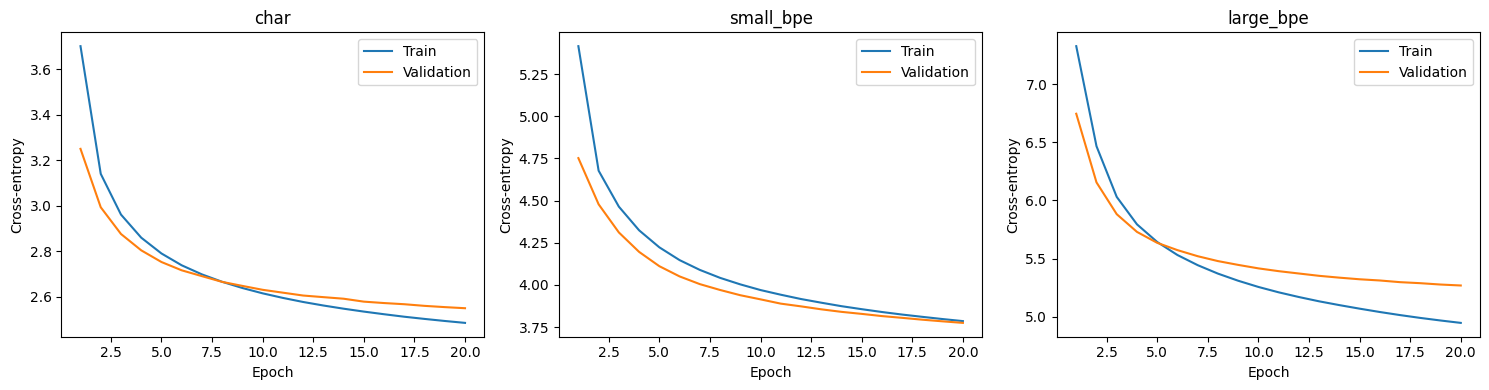

In [29]:
models = ["char", "small_bpe", "large_bpe"]
plt.figure(figsize=(15, 4))

for i,model in enumerate(models):
    with open(f"runs/{model}_history.json") as f:
        result = json.load(f)

    plt.subplot(1, 3, i + 1)
    plt.plot(range(1,len(result["train_loss"])+1),result["train_loss"],label="Train")
    plt.plot(range(1,len(result["val_loss"])+1),result["val_loss"],label="Validation")
    plt.title(model)
    plt.xlabel("Epoch")
    plt.ylabel("Cross-entropy")
    plt.legend()

plt.tight_layout()
plt.savefig("curves.png")
plt.show()
        